# Bài 2: Kiểm định ADF trên chuỗi gốc

**Mục tiêu:** chạy kiểm định Augmented Dickey-Fuller (`adfuller`) trên chuỗi doanh số gốc `a10`, trích xuất ADF Statistic, p-value, Critical Values (1%, 5%, 10%) và kết luận tính dừng.

- $H_0$: chuỗi **có nghiệm đơn vị** (không dừng).
- $H_1$: chuỗi **dừng**.

In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings('ignore', category=FutureWarning)  # ẩn cảnh báo về kiểu trả về của adfuller

## 1. Load dữ liệu (giống Bài 1)

In [2]:
df = pd.read_csv("../data/raw/a10.csv", parse_dates=['date'], index_col='date')
df.index.freq = 'MS'
series = df['value']

print(f"Số quan sát: {len(series)}")
print(f"Giai đoạn: {series.index.min():%m/%Y} -> {series.index.max():%m/%Y}")
print(f"Giá trị thiếu: {series.isna().sum()}")

Số quan sát: 204
Giai đoạn: 07/1991 -> 06/2008
Giá trị thiếu: 0


## 2. Chạy kiểm định ADF

Dùng `regression='c'` (mặc định: có hằng số) và `autolag='AIC'` để tự chọn số độ trễ.

In [3]:
result = adfuller(series, regression='c', autolag='AIC')

adf_stat, p_value, used_lag, n_obs, crit_values = result[0], result[1], result[2], result[3], result[4]
icbest = result[5]

## 3. Trích xuất các chỉ số

In [4]:
print("=" * 45)
print("KẾT QUẢ KIỂM ĐỊNH ADF - CHUỖI GỐC")
print("=" * 45)
print(f"ADF Statistic        : {adf_stat:.4f}")
print(f"p-value              : {p_value:.4f}")
print(f"Số lag sử dụng       : {used_lag}")
print(f"Số quan sát dùng     : {n_obs}")
print("Critical Values:")
for key, value in crit_values.items():
    print(f"   {key:>3} : {value:.4f}")

KẾT QUẢ KIỂM ĐỊNH ADF - CHUỖI GỐC
ADF Statistic        : 3.1452
p-value              : 1.0000
Số lag sử dụng       : 15
Số quan sát dùng     : 188
Critical Values:
    1% : -3.4656
    5% : -2.8770
   10% : -2.5750


In [5]:
# Bảng tổng hợp: so sánh ADF Statistic với từng mốc tới hạn
summary = pd.DataFrame({
    'Mức ý nghĩa': list(crit_values.keys()),
    'Giá trị tới hạn': [round(v, 4) for v in crit_values.values()],
})
summary['ADF Statistic'] = round(adf_stat, 4)
summary['ADF < Critical?'] = adf_stat < summary['Giá trị tới hạn']
summary['Quyết định'] = summary['ADF < Critical?'].map({True: 'Bác bỏ H0', False: 'Không bác bỏ H0'})
summary

,Mức ý nghĩa,Giá trị tới hạn,ADF Statistic,ADF < Critical?,Quyết định
0,1%,-3.4656,3.1452,False,Không bác bỏ H0
1,5%,-2.8770,3.1452,False,Không bác bỏ H0
2,10%,-2.5750,3.1452,False,Không bác bỏ H0


## 4. Kết luận tự động theo quy tắc p-value (α = 0.05)

In [6]:
alpha = 0.05
print(f"p-value = {p_value:.4f}  {'<' if p_value < alpha else '>='}  alpha = {alpha}")
if p_value < alpha:
    print("=> Bác bỏ H0: chuỗi DỪNG.")
else:
    print("=> Không bác bỏ H0: chuỗi KHÔNG DỪNG (có nghiệm đơn vị).")

p-value = 1.0000  >=  alpha = 0.05
=> Không bác bỏ H0: chuỗi KHÔNG DỪNG (có nghiệm đơn vị).


## 5. Trực quan hoá hỗ trợ: Rolling mean / Rolling std (cửa sổ 12 tháng)

Nếu chuỗi dừng, rolling mean và rolling std sẽ xấp xỉ phẳng.

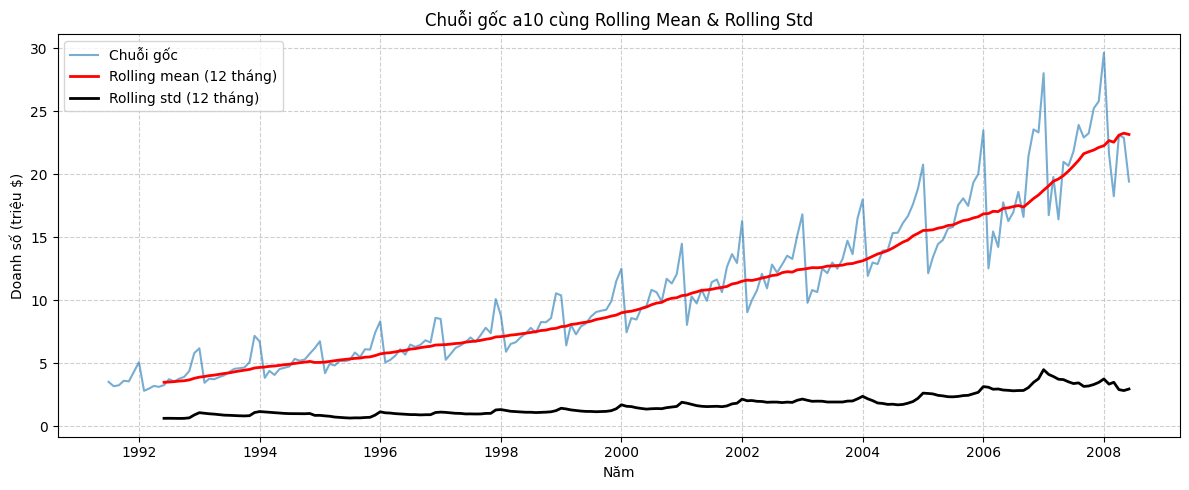

In [7]:
rolling_mean = series.rolling(window=12).mean()
rolling_std = series.rolling(window=12).std()

plt.figure(figsize=(12, 5))
plt.plot(series, color='#1f77b4', alpha=0.6, label='Chuỗi gốc')
plt.plot(rolling_mean, color='red', linewidth=2, label='Rolling mean (12 tháng)')
plt.plot(rolling_std, color='black', linewidth=2, label='Rolling std (12 tháng)')
plt.title('Chuỗi gốc a10 cùng Rolling Mean & Rolling Std')
plt.xlabel('Năm')
plt.ylabel('Doanh số (triệu $)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/02_rolling_stats.png', dpi=300)
plt.show()

## 6. (Tuỳ chọn) Kiểm tra độ bền kết luận với `regression='ct'` (hằng số + xu hướng tuyến tính)

In [8]:
res_ct = adfuller(series, regression='ct', autolag='AIC')
print(f"ADF Statistic (ct): {res_ct[0]:.4f} | p-value: {res_ct[1]:.4f}")
print({k: round(v, 4) for k, v in res_ct[4].items()})

ADF Statistic (ct): 1.0944 | p-value: 1.0000
{'1%': np.float64(-4.0077), '5%': np.float64(-3.4341), '10%': np.float64(-3.1409)}
